In [86]:
from Influence_Modelling import XsvNetwork, Network, Sampling, Metrics, Heuristics
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import scienceplots 
plt.style.use(["science", "no-latex"])
import seaborn as sns
import time
enron  =XsvNetwork.XsvNetwork("enron")
net = Network.Network("")
net.set_nx(Sampling.mhda_sample(enron.get_nx(), 4000))

In [87]:
print(net.get_nx().nodes)

['12889', '2935', '31977', '35055', '10395', '29813', '22378', '7428', '30052', '13201', '29263', '16223', '23432', '2599', '26718', '1428', '7546', '11627', '5203', '550', '217', '26721', '22060', '261', '18724', '6917', '3826', '30672', '9122', '23383', '21856', '17005', '6518', '1946', '6372', '1076', '10605', '16782', '3186', '14381', '2001', '635', '2713', '785', '16086', '9909', '3498', '1147', '8699', '33107', '23357', '19792', '23143', '1913', '271', '8006', '10140', '35842', '31224', '19088', '5444', '6674', '7549', '1459', '15231', '22155', '1874', '984', '1939', '23988', '9898', '1343', '27237', '10231', '12668', '20760', '22916', '29007', '19283', '418', '2509', '481', '1365', '2294', '2176', '8341', '26731', '27171', '4694', '15046', '779', '7556', '18366', '4846', '2752', '401', '7165', '36507', '19359', '20701', '16933', '16403', '26462', '520', '773', '7774', '6736', '1068', '3982', '408', '24692', '15174', '5375', '3945', '18748', '23196', '801', '29849', '3728', '4171

In [107]:
#sizes = [x for x in range(1, 100, 8)]
sizes = [3, 5, 7]

In [108]:
deg = [net.run_ICC(Heuristics.double_deg_discount_h(net.get_nx(), size)) for size in sizes]
deg_nets = [de[1] for de in deg]

deg_discount = [net.run_ICC(Heuristics.double_deg_discount_h(net.get_nx(), size)) for size in sizes]
deg_discount_nets = [de[1] for de in deg_discount]

clust = [net.run_ICC(Heuristics.local_clustering_coefficient_h(net.get_nx(), size)) for size in sizes]
clust_nets = [de[1] for de in clust]

betwe = [net.run_ICC(Heuristics.betweenness_centrality_h(net.get_nx(), size)) for size in sizes]
betwe_nets = [de[1] for de in betwe]

In [109]:
katz= [net.run_ICC(Heuristics.katz_centrality_h(net.get_nx(), size)) for size in sizes]
katz_nets = [de[1] for de in katz]

eigen = [net.run_ICC(Heuristics.katz_centrality_h(net.get_nx(), size)) for size in sizes]
eigen_nets = [de[1] for de in eigen]


In [ ]:
def compute_intersection(G1, G2):
  g1 = set([v for (v, u) in G1.nodes(data = True) if u['status'] != "inactive"])
  g2 = set([v for (v, u) in G2.nodes(data = True) if u['status'] !="inactive"])
  return len(list(set.intersection(g1, g2))) / (0.5 * (len(g1) + len(g2)))

In [59]:
sum([compute_intersection(deg_nets[i], deg_discount_nets[i]) for i in range(len(sizes))]) / len(sizes)

0.6704886343423104

In [62]:
def compute_intersection(G1, G2):
    g1 = {v for (v, u) in G1.nodes(data=True) if u['status'] != "inactive"}
    g2 = {v for (v, u) in G2.nodes(data=True) if u['status'] != "inactive"}
    
    inter = g1.intersection(g2)
    score = len(inter) / (0.5 * (len(g1) + len(g2)))
    
    return inter, score

In [63]:
def pairwise_intersections(graphs):
    names = list(graphs.keys())
    matrix = []

    for g1_name in names:
        row = []
        for g2_name in names:
            _, score = compute_intersection(graphs[g1_name], graphs[g2_name])
            row.append(score)
        matrix.append(row)

    return names, np.array(matrix)

<Axes: >

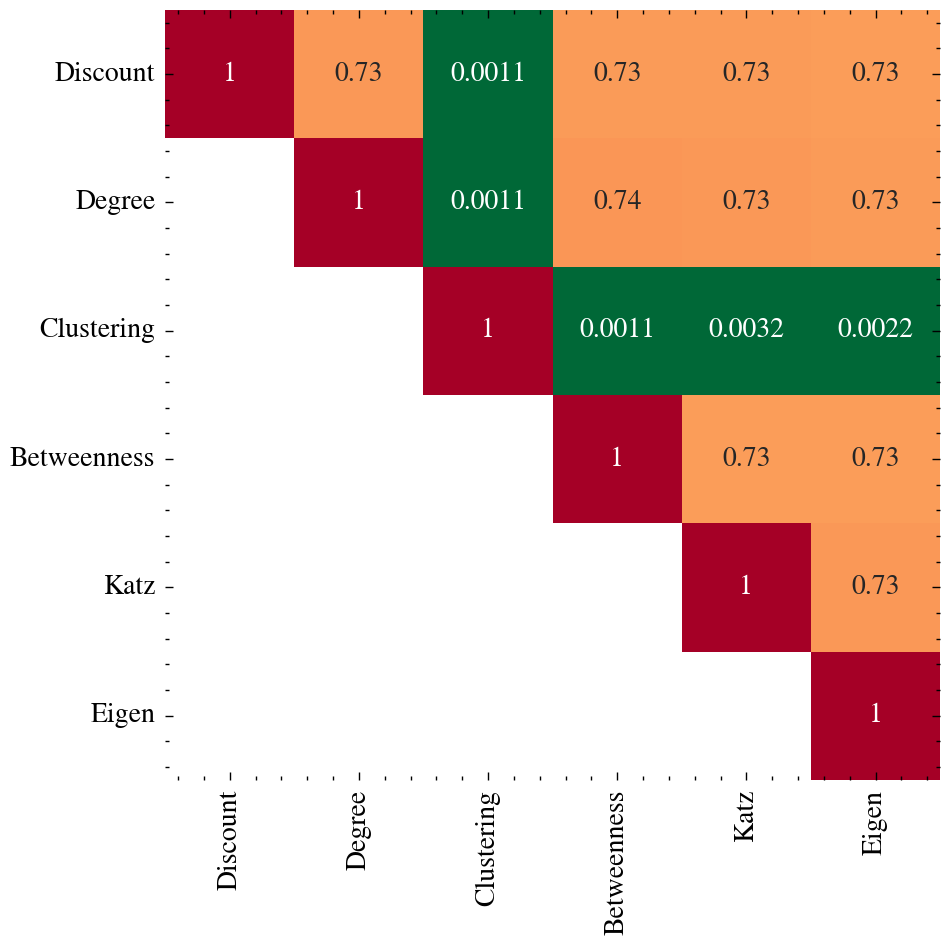

In [119]:
i = 2
names, matrix = pairwise_intersections({"Discount":deg_discount_nets[i], "Degree":deg_nets[i], "Clustering": clust_nets[i], "Betweenness": betwe_nets[i], "Katz": katz_nets[i], "Eigen": eigen_nets[i]})
fig, ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(5, 5)
sns.heatmap(matrix, annot=True, xticklabels=names, yticklabels=names, mask=np.tril(np.ones_like(matrix, dtype=bool), k=-1), cmap="RdYlGn_r", cbar=False)

In [51]:
deg_discount_nets[0].nodes(data=True)

NodeDataView({'5680': {'status': 'used'}, '30476': {'status': 'inactive'}, '13227': {'status': 'inactive'}, '14821': {'status': 'inactive'}, '21985': {'status': 'inactive'}, '1836': {'status': 'inactive'}, '1233': {'status': 'used'}, '470': {'status': 'used'}, '4513': {'status': 'used'}, '4376': {'status': 'used'}, '5750': {'status': 'used'}, '137': {'status': 'inactive'}, '35956': {'status': 'inactive'}, '1579': {'status': 'inactive'}, '14039': {'status': 'used'}, '8565': {'status': 'inactive'}, '19446': {'status': 'inactive'}, '1428': {'status': 'inactive'}, '24762': {'status': 'inactive'}, '17288': {'status': 'inactive'}, '24926': {'status': 'inactive'}, '551': {'status': 'used'}, '550': {'status': 'inactive'}, '5203': {'status': 'used'}, '24726': {'status': 'inactive'}, '4740': {'status': 'used'}, '1242': {'status': 'used'}, '1728': {'status': 'inactive'}, '7728': {'status': 'inactive'}, '13139': {'status': 'inactive'}, '31156': {'status': 'inactive'}, '261': {'status': 'used'}, '2

In [60]:
def find_overlaps(methods, size_set, axis, network):
    intersections = {}
    names = []
    for method in methods:
        name = str(method).split(" ")[1]
        names.append(name)
        seeds = set(method(network, size_set))
        intersections[name] = seeds
    abs_matrix = []
    for name in names:
        row = []
        for other_name in names:
            row.append(
                len(
                    list(
                        set.intersection(intersections[name], intersections[other_name])
                    )
                )
            )
        abs_matrix.append(row)
    scaled = np.array(abs_matrix) / size_set
    axis.set_title("Proportion of Selected Seed Size Intersecting (100 Nodes)")
    sns.heatmap(scaled, annot=True, ax=axis, cmap="RdYlGn_r", cbar=False, xticklabels=names, yticklabels=names, mask=np.tril(np.ones_like(scaled, dtype=bool), k=-1))
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0)

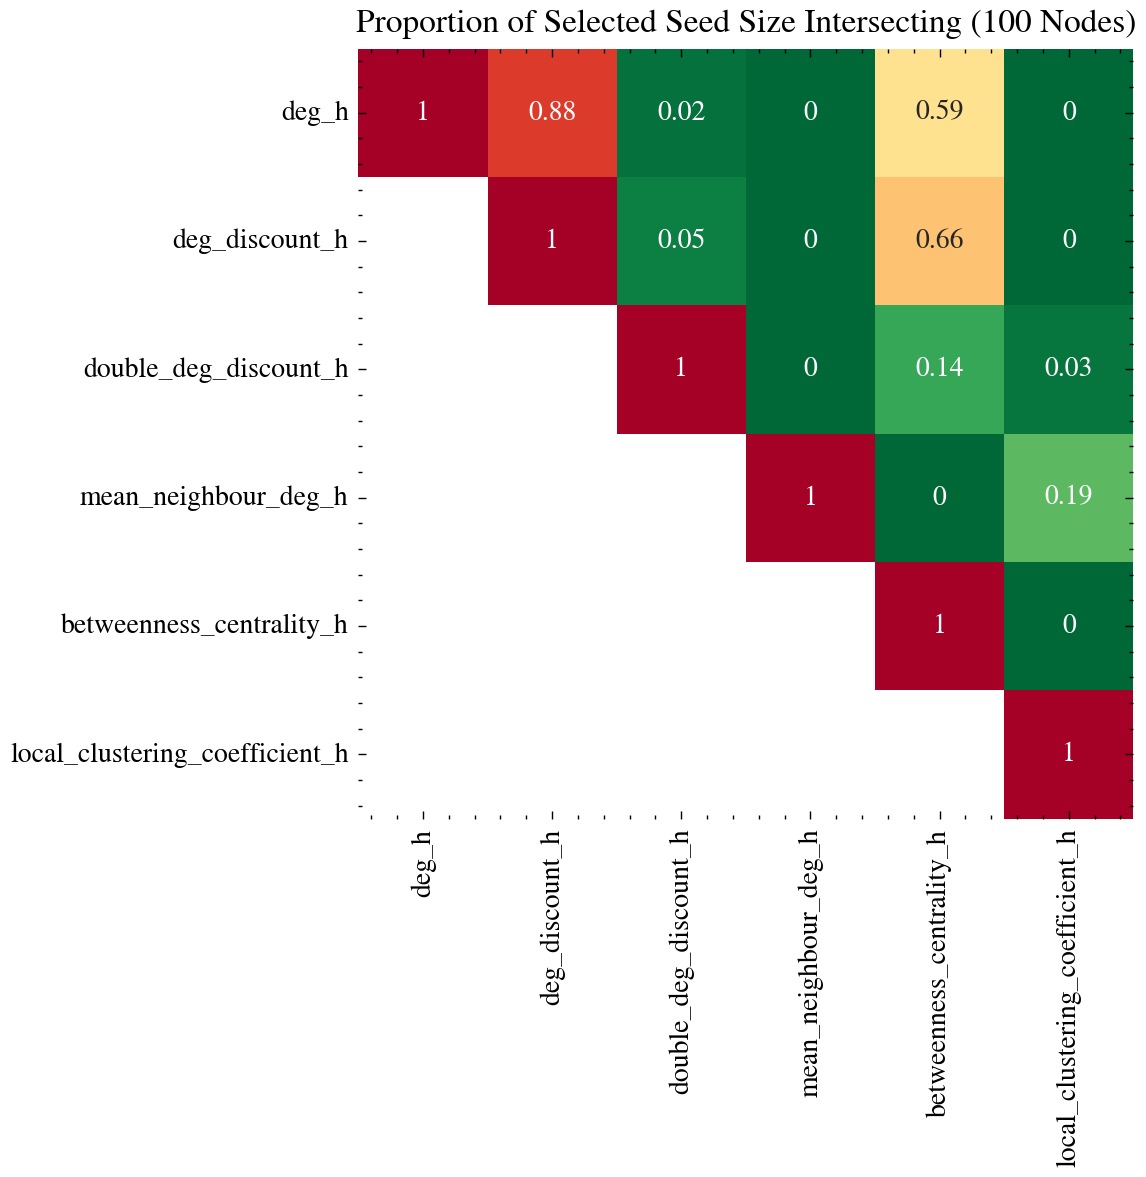

In [ ]:
fig, axs = plt.subplots()
fig.set_size_inches(5,5)
fig.set_dpi(200)
find_overlaps([Heuristics.deg_h, Heuristics.deg_discount_h, Heuristics.double_deg_discount_h, Heuristics.mean_neighbour_deg_h, Heuristics.betweenness_centrality_h, Heuristics.local_clustering_coefficient_h], 100, axs, net.get_nx())